In [4]:
import numpy as np
import json
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [5]:
#base_path = "Dataset/processed/a01_A_impute_simple/"

# 1. Load feature columns and configuration
with open( '../Dataset/processed/a01_A_impute_simple/feature_columns.json', 'r') as f:
    config = json.load(f)

features = config['features']
target = 'is_cancer'  

# 2. Load preprocessed train and test data
train_df = pd.read_csv( '../Dataset/processed/a01_A_impute_simple/final_train.csv')
test_df = pd.read_csv( '../Dataset/processed/a01_A_impute_simple/final_test.csv')

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}\n")

Training set shape: (1838, 24)
Test set shape: (460, 24)



In [6]:

# ALGORITHM 1: Random Forest Classifier

print("Training Random Forest ")
rf_model = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1] # Probability of positive class (cancer=1)
print(f"Random Forest Accuracy: {accuracy_score(y_test, rf_preds):.4f}")
print("Classification Report:")
print(classification_report(y_test, rf_preds))

Training Random Forest 


NameError: name 'rf_preds' is not defined

In [47]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix (Array format):")
print(conf_matrix)

Confusion Matrix (Array format):
[[198  39]
 [ 41 182]]


In [48]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, log_loss, confusion_matrix

In [49]:
print("="*50)
print("1. EVALUATION ON HOLD-OUT TEST SET (ALL METRICS)")
print("="*50)

# Calculate all possible metrics
acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')
roc_auc = roc_auc_score(y_test, y_prob)
logloss = log_loss(y_test, y_prob)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy:       {acc:.4f}")
print(f"Precision:      {precision:.4f}")
print(f"Recall:         {recall:.4f}")
print(f"F1-Score:       {f1:.4f}")
print(f"ROC-AUC Score:  {roc_auc:.4f}")
print(f"Log Loss:       {logloss:.4f}\n")

print("Confusion Matrix:")
print(conf_matrix)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

print("="*50)
print("2. EVALUATION ON MULTIPLE ANGLES: K-FOLD CROSS-VALIDATION")
print("="*50)

1. EVALUATION ON HOLD-OUT TEST SET (ALL METRICS)
Accuracy:       0.8261
Precision:      0.8261
Recall:         0.8261
F1-Score:       0.8261
ROC-AUC Score:  0.9051
Log Loss:       0.7565

Confusion Matrix:
[[198  39]
 [ 41 182]]

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83       237
           1       0.82      0.82      0.82       223

    accuracy                           0.83       460
   macro avg       0.83      0.83      0.83       460
weighted avg       0.83      0.83      0.83       460

2. EVALUATION ON MULTIPLE ANGLES: K-FOLD CROSS-VALIDATION


In [32]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [50]:
# Combine train and test for rigorous cross-validation across folds, 

X_all = pd.concat([X_train, X_test])
y_all = pd.concat([y_train, y_test])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_accuracies = cross_val_score(rf_model, X_all, y_all, cv=cv, scoring='accuracy')
cv_f1 = cross_val_score(rf_model, X_all, y_all, cv=cv, scoring='f1_weighted')
cv_roc_auc = cross_val_score(rf_model, X_all, y_all, cv=cv, scoring='roc_auc')

print(f"5-Fold CV Accuracies: {np.round(cv_accuracies, 4)}")
print(f"Mean CV Accuracy:     {cv_accuracies.mean():.4f} (±{cv_accuracies.std():.4f})")
print(f"Mean CV F1-Score:     {cv_f1.mean():.4f} (±{cv_f1.std():.4f})")
print(f"Mean CV ROC-AUC:      {cv_roc_auc.mean():.4f} (±{cv_roc_auc.std():.4f})")

5-Fold CV Accuracies: [0.8435 0.8543 0.8739 0.8758 0.8671]
Mean CV Accuracy:     0.8629 (±0.0123)
Mean CV F1-Score:     0.8630 (±0.0123)
Mean CV ROC-AUC:      0.9259 (±0.0104)


In [51]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

Random Forest ROC-AUC Score: 0.9051


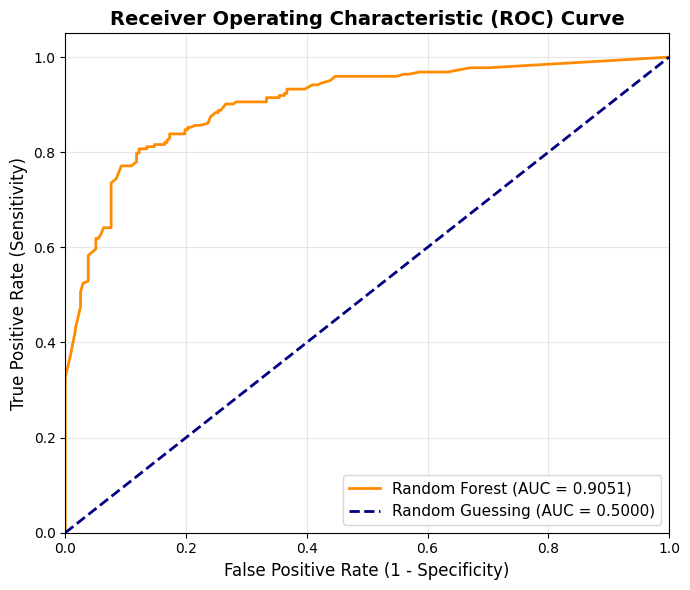

In [52]:
# Calculate ROC-AUC score
auc_val = roc_auc_score(y_test, y_prob)
print(f"Random Forest ROC-AUC Score: {auc_val:.4f}")
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# 6. Plotting the ROC curve
plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    color="darkorange",
    lw=2,
    label=f"Random Forest (AUC = {auc_val:.4f})",
)
plt.plot(
    [0, 1],
    [0, 1],
    color="navy",
    lw=2,
    linestyle="--",
    label="Random Guessing (AUC = 0.5000)",
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12)
plt.title(
    "Receiver Operating Characteristic (ROC) Curve", fontsize=14, fontweight="bold"
)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()

# Save and display
plt.savefig("roc_auc_curve.png", dpi=300)
plt.show()

In [ ]:

# ALGORITHM 2: Logistic Regression

print("\n--- Training Logistic Regression ---")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

lr_preds = lr_model.predict(X_test)
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, lr_preds):.4f}")
print("Classification Report:")
print(classification_report(y_test, lr_preds))


--- Training Logistic Regression ---
Logistic Regression Accuracy: 0.8565
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.85      0.86       237
           1       0.85      0.86      0.85       223

    accuracy                           0.86       460
   macro avg       0.86      0.86      0.86       460
weighted avg       0.86      0.86      0.86       460

